In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.PhoenixModels import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.BaseLineModels import AlwaysDerivativeZero

from halcyon.Models.CellBox import CellBox
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel
from halcyon.Trainer import Trainer
from halcyon.FittedTrainerList import FittedTrainerList
from halcyon.Losses import MSELossPlusMachineLearningL2
from halcyon.TidyDfResults import TidyDfResults
from copy import deepcopy
from halcyon.Simulators.GNWSimRunner import SimulationResult, NoiseLevel

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Simulating data

In [2]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [100]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [5]
sparsity_list = [0.1]
out_path = Path("../data/hybrid_model_with_noise") 

In [3]:
sim_outputs: list[SimulationResult] = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=False,
                noise_level=NoiseLevel.ALLNOISE,
            )
            sim_outputs.append(sim_output) 
sim_outputs

2026-01-26 11:28:43,627 - INFO - Generating network
2026-01-26 11:28:47,744 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_17*Node_5*Node_2) + ~(Node_28*Node_19*Node_4) + ~(Node_29*Node_13~Node_24)
my_network: Node_1: ~(Node_15*Node_71~Node_20~Node_50) + ~(Node_8*Node_0) + (Node_31) + ~(Node_11)
my_network: Node_2: (Node_30) + (Node_12~Node_1) + (Node_37) + (Node_3*Node_23~Node_35) + ~(Node_7) + (Node_17) + ~(Node_6)
my_network: Node_3: (Node_30*Node_7~Node_6~Node_17) + ~(Node_23*Node_37*Node_2~Node_35) + ~(Node_12*Node_53*Node_43)
my_network: Node_4: (Node_28*Node_5~Node_24) + ~(Node_1*Node_19~Node_0~Node_9)
my_network: Node_5: ~(Node_19*Node_57*Node_29~Node_13) + (Node_4*Node_0) + ~(Node_24)
my_network: Node_6: (Node_3*Node_61*Node_37) + (No

[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), network_name='my_network', nr_genes=100, nr_modules=5, sparsity=0.1, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7fe1e25a37f0>, noise_level=<NoiseLevel.ALLNOISE: '_'>)]

In [4]:
sim_output = sim_outputs[0]
# Do clustering
sim_output.network.do_clustering()

1


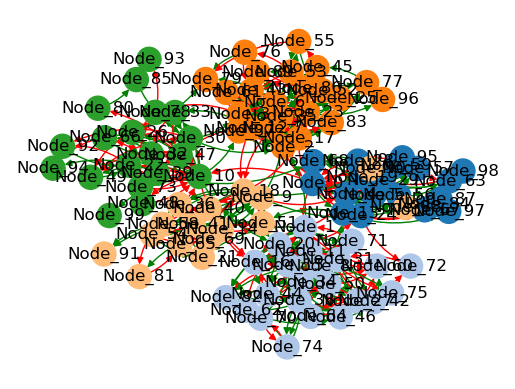

In [5]:
from networkx import number_weakly_connected_components
print(number_weakly_connected_components(sim_output.network._graph))

sim_output.network.plot()
plt.show()

In [6]:
for i, module in enumerate(sim_output.network._clustering):
    if 'Node_93' in module:
        print('Module:', i)
        print('Size:', len(module))
        genes_to_select = list(sim_output.network._clustering[i])
        break

Module: 4
Size: 19


In [7]:
genes_to_select

['Node_47',
 'Node_93',
 'Node_39',
 'Node_85',
 'Node_33',
 'Node_78',
 'Node_22',
 'Node_49',
 'Node_10',
 'Node_80',
 'Node_99',
 'Node_26',
 'Node_94',
 'Node_32',
 'Node_92',
 'Node_66',
 'Node_48',
 'Node_73',
 'Node_30']

So select module 4 now for funsies

# Trainers (with different models) creation

In [8]:
train_jobs : list[Trainer] = []

## Mech model

In [9]:
# Generate MM from this
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml',
                           condition_names=(), from_gnw=True, device='cuda:1')
# Select only genes from specific module
mm.select_genes(genes_to_select, goldstandard_signed_file_for_expression_substitution  = sim_output.data_path / f'{network_name}_goldstandard_signed.tsv')
# Fit MM on this data (skip for now?)
print(mm.modelled_gene_labels)
# Creating MM trainer even though it cannot be trained
mm_trainer = Trainer(
    mm,
    sim_output,
    batch_size=32,
    nr_training_steps=0,
    # optimizer_fn=lambda x: None
)

train_jobs.append(mm_trainer)
# mm_trainer.save(mm_trainer.save_path)

2026-01-26 11:30:03,448 - INFO - Loading SBML model from: /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/my_network.xml


['Node_47', 'Node_93', 'Node_39', 'Node_85', 'Node_33', 'Node_78', 'Node_22', 'Node_49', 'Node_10', 'Node_80', 'Node_99', 'Node_26', 'Node_94', 'Node_32', 'Node_92', 'Node_66', 'Node_48', 'Node_73', 'Node_30']


## ML and Hybrid model

In [10]:

expr_data = sim_output.get_ko_timeseries_expressiondata()

# for hidden_size in [2, 5, 10]:
#     for do_only_pos in [True, False]:

for hidden_size in [20, 50]:
    for do_only_pos in [True]:        
        ml_model = PhoenixAddAndProdLayers(
                    modelled_gene_labels=expr_data.genes,
                    hidden_size=hidden_size,
                    condition_names=expr_data.all_environments,
                    synthesis_only_positive=do_only_pos,
                    device='cuda:1'
            )

        # trainer = Trainer(
        #     ml_model,
        #     sim_output,
        #     batch_size=32,
        #     nr_training_steps=1000,
        # )

        # train_jobs.append(trainer)
        # Create hybrid model with MM and cellbox with add and prod
        hybrid_model = HybridModel(deepcopy(mm), deepcopy(ml_model), device='cuda:1')



        for model in [ml_model, hybrid_model]:
            # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
            trainer = Trainer(
                model,
                sim_output,
                batch_size=32,
                nr_training_steps=20,
                optimizer_kwargs = {'lr': 0.1}
            )
            train_jobs.append(trainer)

## Baseline model (always derivative of 0)

In [11]:
baseline_model = AlwaysDerivativeZero(modelled_gene_labels=expr_data.genes,
    condition_names=expr_data.all_environments)

trainer = Trainer(
    baseline_model,
    sim_output,
    batch_size=32,
    nr_training_steps=0,
)
train_jobs.append(trainer)

2026-01-26 11:33:06,657 - INFO - Using GPU: Tesla T4 (compute capability 7.5)


In [12]:
for job in train_jobs:
    print(job)
    print()

Training PyTorchODE on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), network_name='my_network', nr_genes=100, nr_modules=5, sparsity=0.1, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7fe1e25a37f0>, noise_level=<NoiseLevel.ALLNOISE: '_'>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/trained_trainer_PyTorchODE.pt

Training PhoenixAddAndProdLayers on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), network_name='my_network', nr_genes=100, nr_modules=5, sparsity=0.1, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7fe1e25a37f0>, noise_level=<NoiseLevel.ALLNOISE: '_'>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_mo

# Do training

In [ ]:
train_jobs[3].run_for_parallelisation_and_save()

In [13]:
mp.set_start_method("spawn", force=True)
with mp.Pool(processes=4) as pool:
    pool.map(run_training_job, train_jobs)

/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/sympy/core/sympify.py:449: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  return sympify(float(a))
2026-01-26 11:33:53,931 [SpawnPoolWorker-2] Epoch 0, loss 0.07437846250832081
2026-01-26 11:33:57,917 [SpawnPoolWorker-4] Epoch 0, loss 0.18710761796683073
2026-01-26 11:34:03,908 [SpawnPoolWorker-2] Epoch 1, loss 0.027271883096545935
2026-01-26 11:34:16,599 [SpawnPoolWorker-2] Epoch 2, loss 0.018923708703368902
2026-01-26 11:34:23,131 [SpawnPoolWorker-4] Epoch 1, loss 0.09186454303562641
2026-01-26 11:34:29,445 [SpawnPoolWorker-2] Epoch 3, loss 0.015357091557234526
2026-01-26 11:34:43,947 [SpawnPoolWorker-2] Epoch 4, loss 0.012405523331835866
2026-01-26 11:34:55,364 [SpawnPoolWorker-4] Epoch 2, loss 0.037527207285165

MaybeEncodingError: Error sending result: '[{'final_loss': 0.006807381985709071, 'nr_training_steps': 20, 'model_path': '/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/trained_trainer_PhoenixAddAndProdLayers_hidden_size_20_synthesis_only_positive_True_lr_0.1.pt', 'model_cls': 'PhoenixAddAndProdLayers', 'data_path': PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), 'network_name': 'my_network', 'nr_genes': 100, 'nr_modules': 5, 'sparsity': 0.1, 'keep_self_interactions': False, 'network': <halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f9ee05e4520>, 'noise_level': <NoiseLevel.ALLNOISE: '_'>, 'device': device(type='cuda', index=1), 'hidden_size': 20, 'synthesis_only_positive': tensor(True, device='cuda:1'), 'lr': 0.1}]'. Reason: 'RuntimeError('Attempted to send CUDA tensor received from another process; this is not currently supported. Consider cloning bef

# Plot results

In [ ]:
train_jobs

In [14]:
# The above implementation works (but doesnt load from saved files)
result_list = FittedTrainerList.load_saved_jobs(train_jobs)

2026-01-26 12:46:52,822 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/trained_trainer_PyTorchODE.pt
2026-01-26 12:46:54,215 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/trained_trainer_PhoenixAddAndProdLayers_hidden_size_20_synthesis_only_positive_True_lr_0.1.pt
2026-01-26 12:46:54,257 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/trained_trainer_HybridModel_hidden_size_20_synthesis_only_positive_True_lr_0.1.pt
2026-01-26 12:46:54,885 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/trained_trainer_PhoenixAddAndProdLayers_hidden_size_50_synthesis_only_positive_True_lr_0.1.pt
2026-01-26 12:46:54,900 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_

## Single KOs

In [15]:
dataset_getter = lambda trainer: trainer.dataset
conditions_to_map = result_list.get_all_genes()[:3]

tidy_df = result_list.predict_tidy_dataframe_for_all_models_specific_kos(
    conditions_to_map, dataset_getter
)

2026-01-26 12:46:58,839 - INFO - Predicting for: Training PhoenixAddAndProdLayers on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), network_name='my_network', nr_genes=100, nr_modules=5, sparsity=0.1, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7fe1e25a37f0>, noise_level=<NoiseLevel.ALLNOISE: '_'>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/trained_trainer_PhoenixAddAndProdLayers_hidden_size_20_synthesis_only_positive_True_lr_0.1.pt
100%|██████████| 3/3 [00:13<00:00,  4.46s/it]
2026-01-26 12:47:12,241 - INFO - Predicting for: Training HybridModel on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), network_name='my_network', nr_genes=100, nr_modules=5, sparsity=0.1, keep_self

In [16]:
tidy_df.df.head()

,gene,time,expression,model,condition
0,Node_0,0.0,0.467964,ground_truth,KO: Node_10
1,Node_1,0.0,0.607046,ground_truth,KO: Node_10
2,Node_2,0.0,0.371550,ground_truth,KO: Node_10
3,Node_3,0.0,0.243491,ground_truth,KO: Node_10
4,Node_4,0.0,0.390211,ground_truth,KO: Node_10


In [17]:
tidy_df.to_csv(out_path / "tidy_df_single_ko_predictions.csv")

In [18]:
# example_genes = ['Node_99', 'Node_85', 'Node_48', 'Node_66', 'Node_12']

example_genes = ['Node_0', 'Node_1', 'Node_2']

In [19]:
tidy_df.df = tidy_df.df[(tidy_df.df['gene'].isin(example_genes))]

In [22]:
def quick_rename_of_cols(model_name):
    return model_name.replace('_synthesis_only_positive_True_lr_0.1', '').replace('_hidden_size_', '_h_')

In [23]:
tidy_df.df.model = tidy_df.df.model.apply(quick_rename_of_cols)

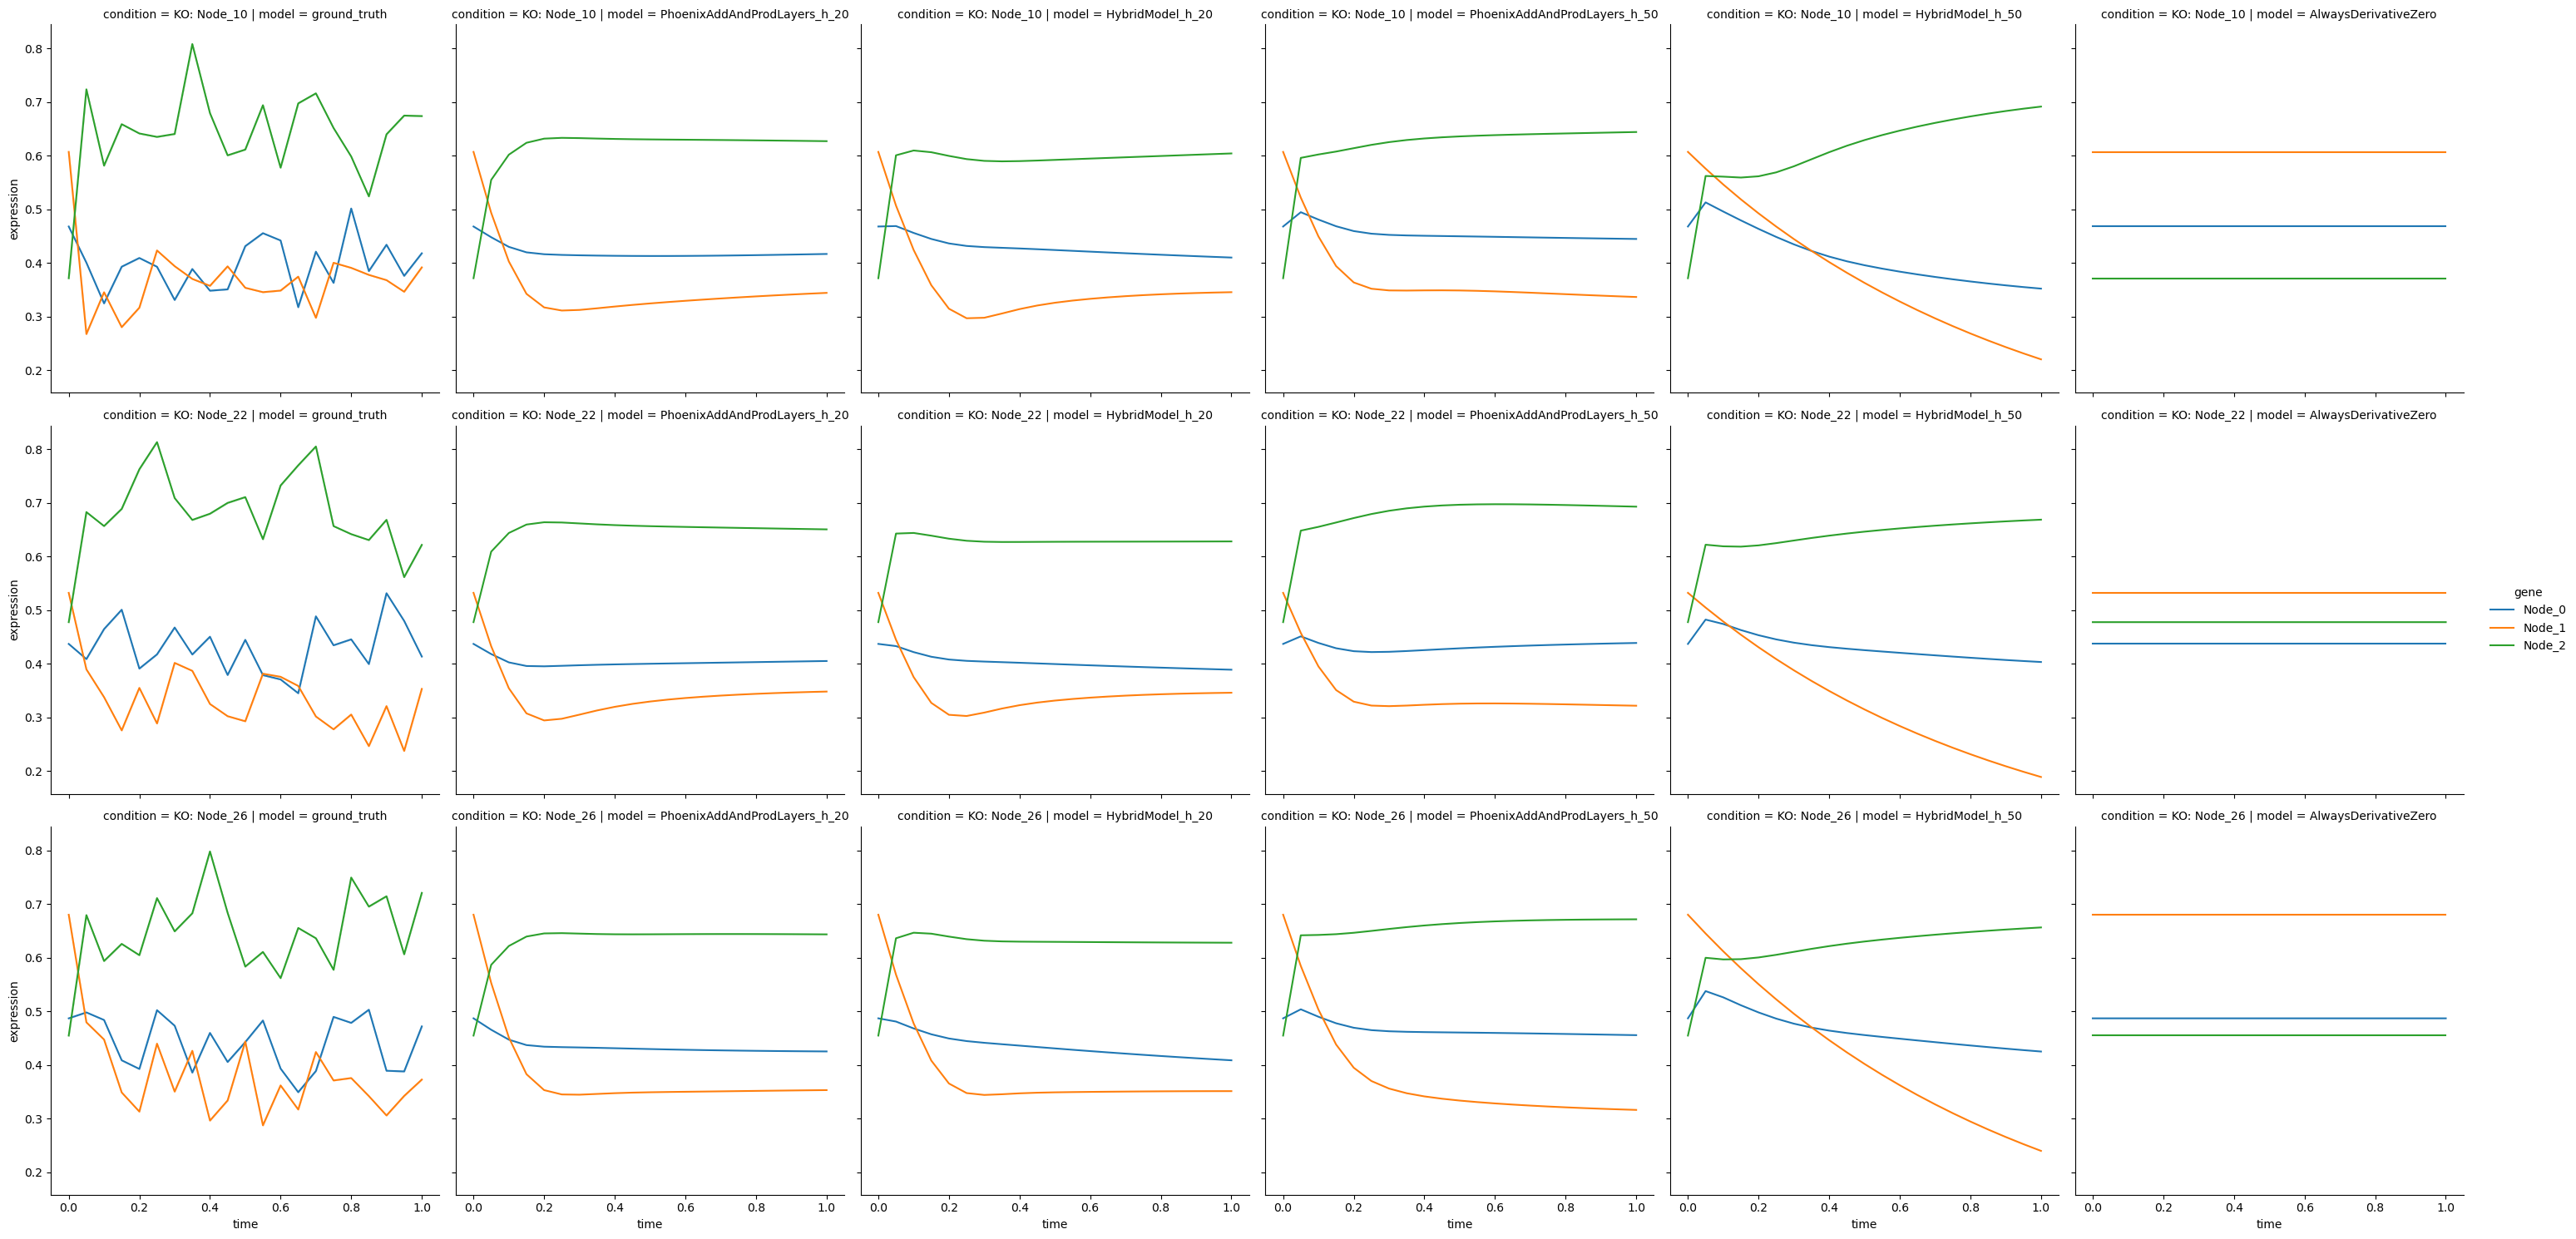

In [25]:
tidy_df.plot_model_plots()

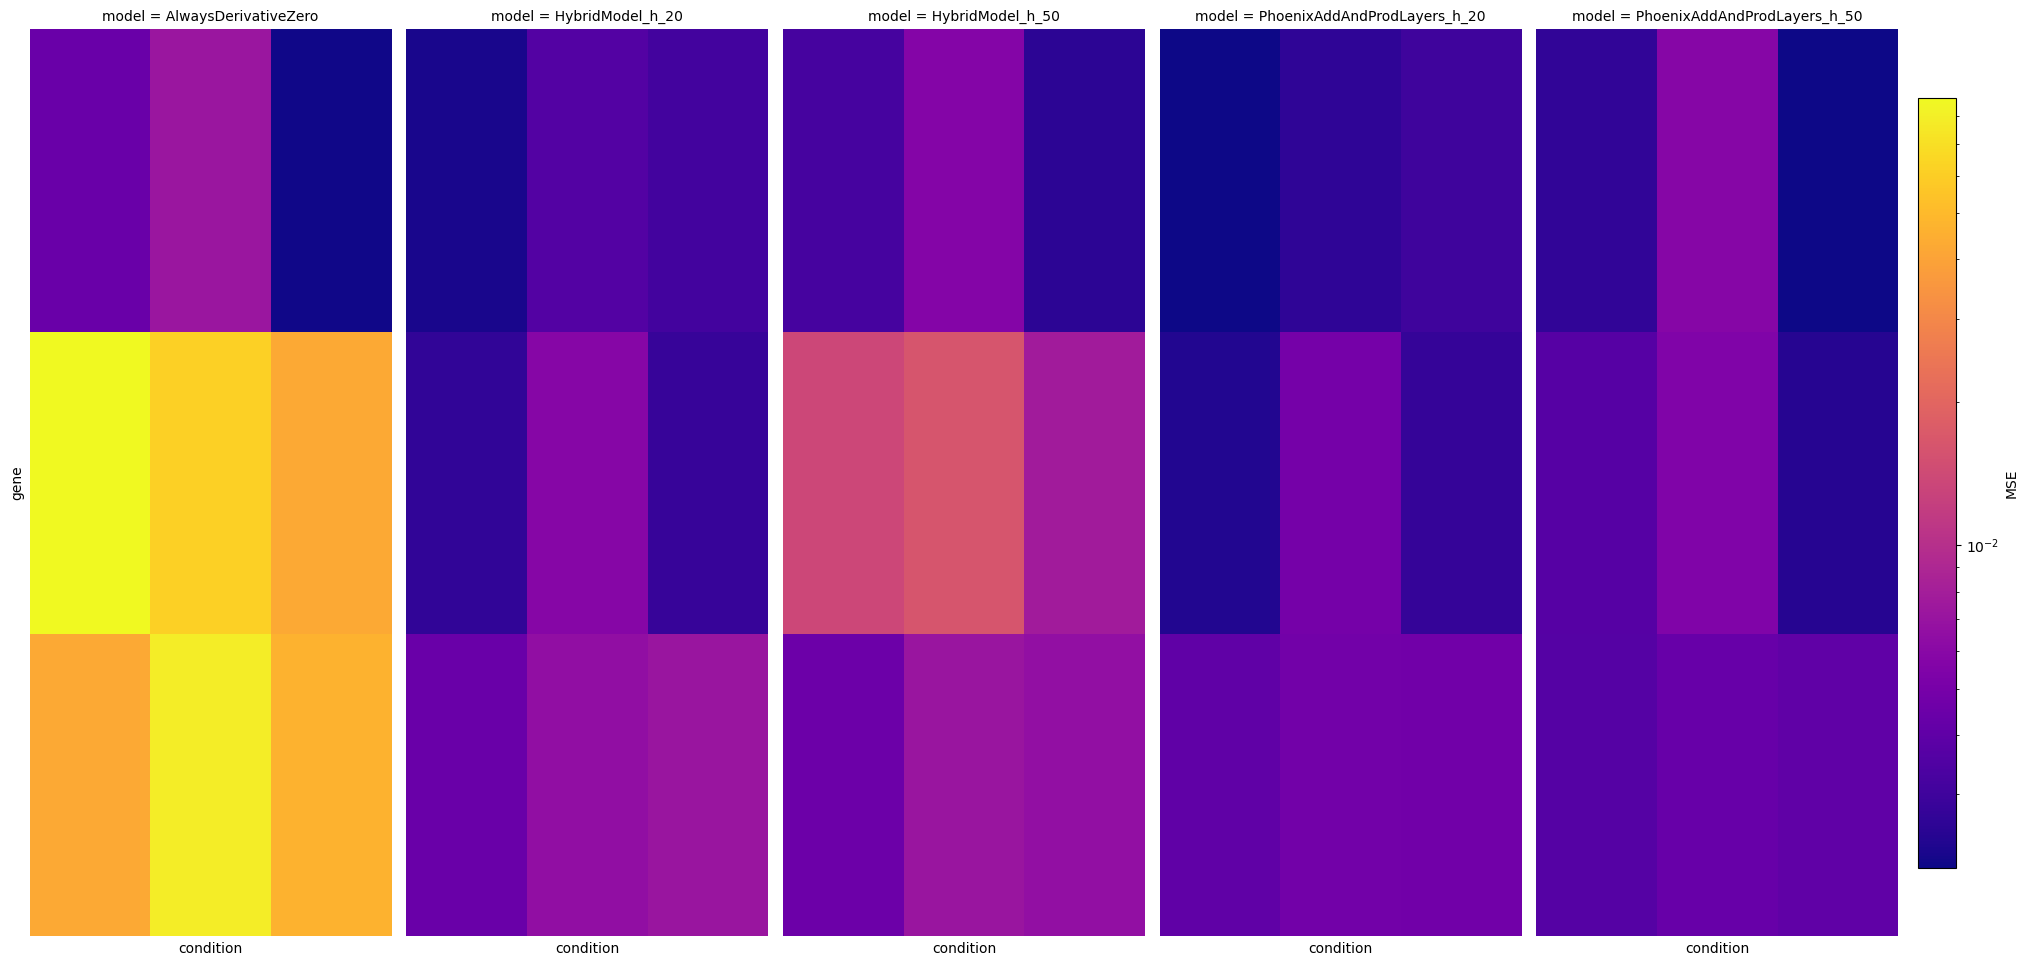

In [24]:
tidy_df.per_gene_mse_heatmap(robust=True,cmap='plasma')

In [ ]:
tidy_df = TidyDfResults.from_csv(out_path / "tidy_df_single_ko_predictions.csv")

In [31]:
fig_dir = out_path / 'figures'
fig_dir

PosixPath('../data/hybrid_model_with_noise/figures')

In [ ]:
tidy_df.plot_r2()

In [ ]:
tidy_df.plot_mse_per_gene();plt.tight_layout();plt.savefig(fig_dir / 'mse_plot.eps')

In [ ]:
tidy_df.plot_scatterplot()

## Double KOs

In [26]:
dataset_getter = lambda trainer: trainer.double_ko_dataset
conditions_to_map = result_list.get_double_ko_combinations()
len(conditions_to_map)

100

In [27]:
tidy_df_double_ko = result_list.predict_tidy_dataframe_for_all_models_specific_kos(
    conditions_to_map, dataset_getter
)
tidy_df_double_ko.to_csv(out_path / "tidy_df_double_ko_predictions.csv")
# tidy_df.to_parquet(out_path / "tidy_df_single_ko_predictions.parquet")

2026-01-26 13:08:41,488 - INFO - Predicting for: Training PhoenixAddAndProdLayers on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), network_name='my_network', nr_genes=100, nr_modules=5, sparsity=0.1, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7fe1e25a37f0>, noise_level=<NoiseLevel.ALLNOISE: '_'>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/trained_trainer_PhoenixAddAndProdLayers_hidden_size_20_synthesis_only_positive_True_lr_0.1.pt
100%|██████████| 100/100 [04:13<00:00,  2.53s/it]
2026-01-26 13:12:54,720 - INFO - Predicting for: Training HybridModel on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), network_name='my_network', nr_genes=100, nr_modules=5, sparsity=0.1, keep_

In [28]:
tidy_df_double_ko = TidyDfResults.from_csv(out_path / "tidy_df_double_ko_predictions.csv")

In [29]:
tidy_df_double_ko.df.model = tidy_df_double_ko.df.model.apply(quick_rename_of_cols)

FileNotFoundError: [Errno 2] No such file or directory: '../data/hybrid_model_with_noise/figures/double_ko_mse_heatmap.eps'

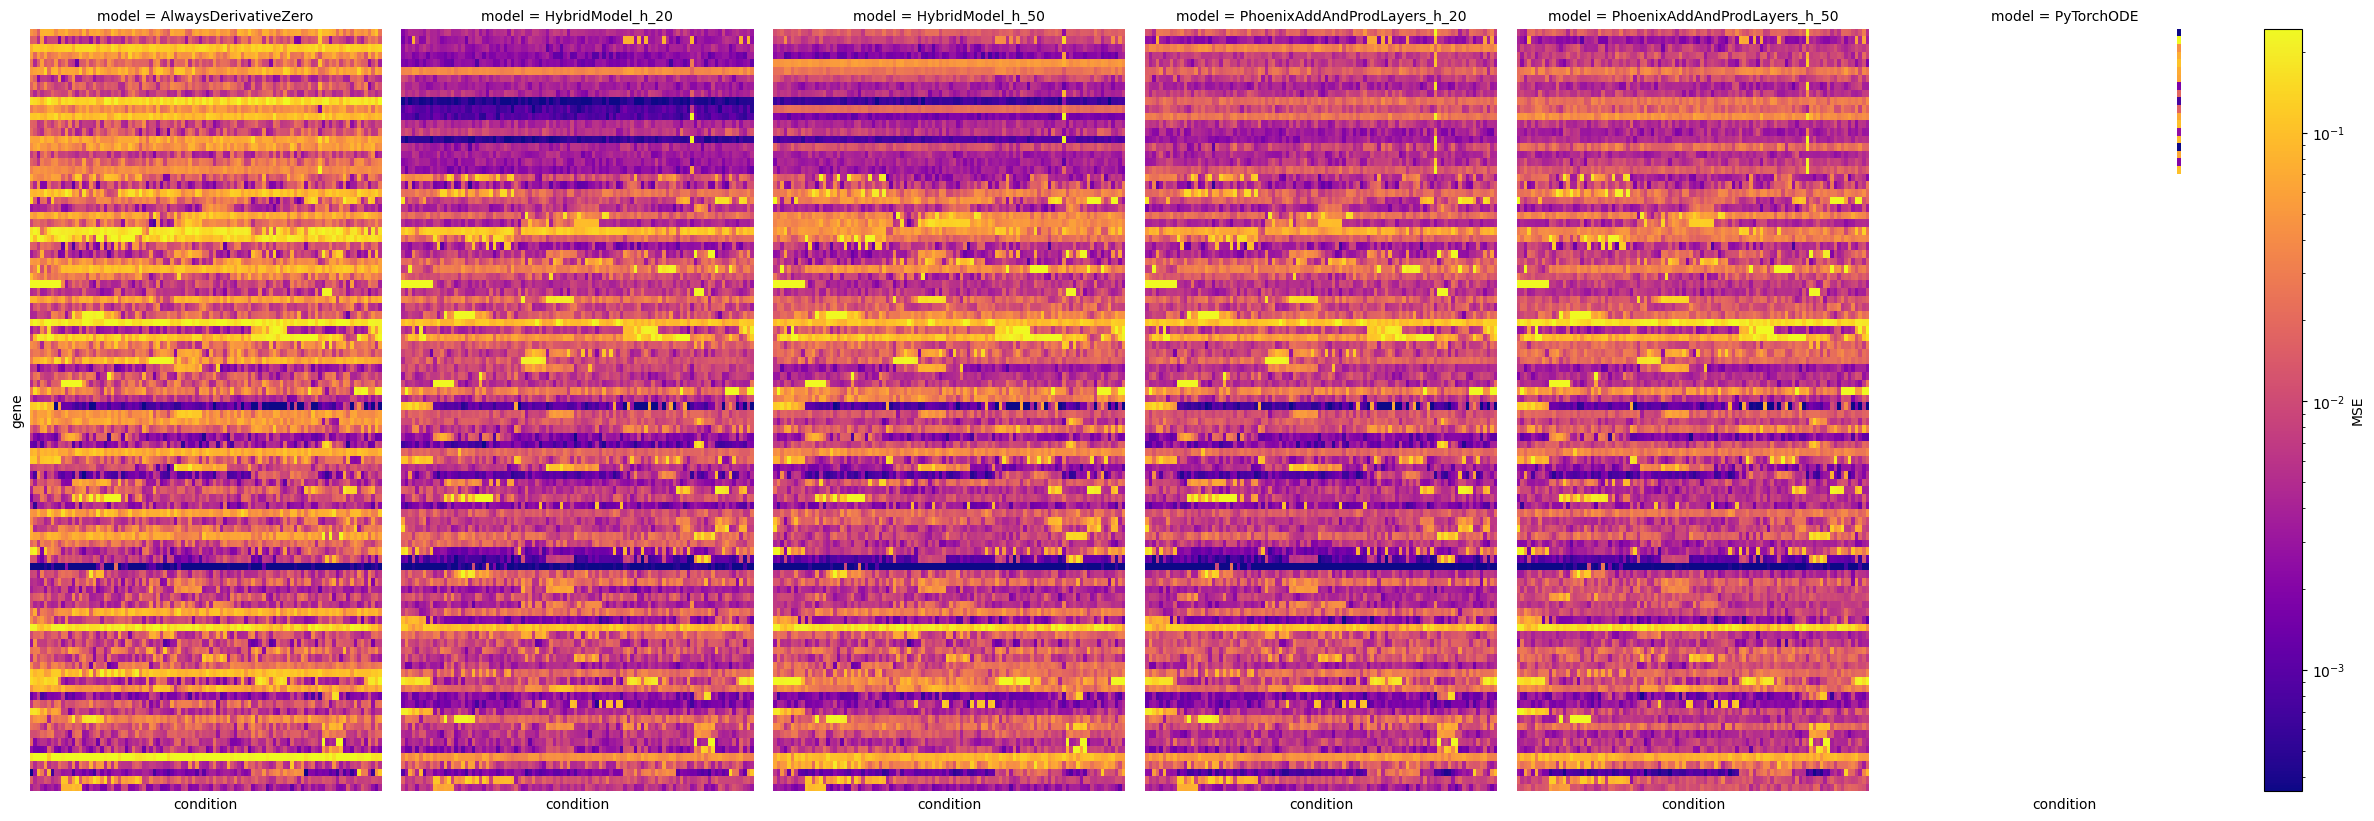

In [ ]:
tidy_df_double_ko.per_gene_mse_heatmap(robust=True,cmap='plasma')


In [ ]:
plt.savefig(fig_dir / 'double_ko_mse_heatmap.eps', bbox_inches='tight')

In [42]:
tidy_df_double_ko.df.head()

,gene,time,expression,model,condition
0,Node_0,0.0,0.333039,ground_truth,"KO: Node_7, Node_12"
1,Node_1,0.0,0.285562,ground_truth,"KO: Node_7, Node_12"
2,Node_2,0.0,0.323621,ground_truth,"KO: Node_7, Node_12"
3,Node_3,0.0,0.500195,ground_truth,"KO: Node_7, Node_12"
4,Node_4,0.0,0.498883,ground_truth,"KO: Node_7, Node_12"


In [48]:
double_ko_genes_to_select = [
    "Node_33",
    "Node_26",
    "Node_32",
    "Node_10",
    "Node_30",
    "Node_22",
    "Node_80",
    "Node_99",
    "Node_92",
    "Node_93",
    "Node_17",
    "Node_0"
]
tidy_df_double_ko.df = tidy_df_double_ko.df[(tidy_df_double_ko.df['gene'].isin(double_ko_genes_to_select)) & (tidy_df_double_ko.df['condition'] == 'KO: Node_10, Node_47')]
tidy_df_double_ko.df.head()

,gene,time,expression,model,condition
96600,Node_0,0.0,0.348359,ground_truth,"KO: Node_10, Node_47"
96610,Node_10,0.0,0.390015,ground_truth,"KO: Node_10, Node_47"
96617,Node_17,0.0,0.662769,ground_truth,"KO: Node_10, Node_47"
96622,Node_22,0.0,0.115025,ground_truth,"KO: Node_10, Node_47"
96626,Node_26,0.0,0.486459,ground_truth,"KO: Node_10, Node_47"


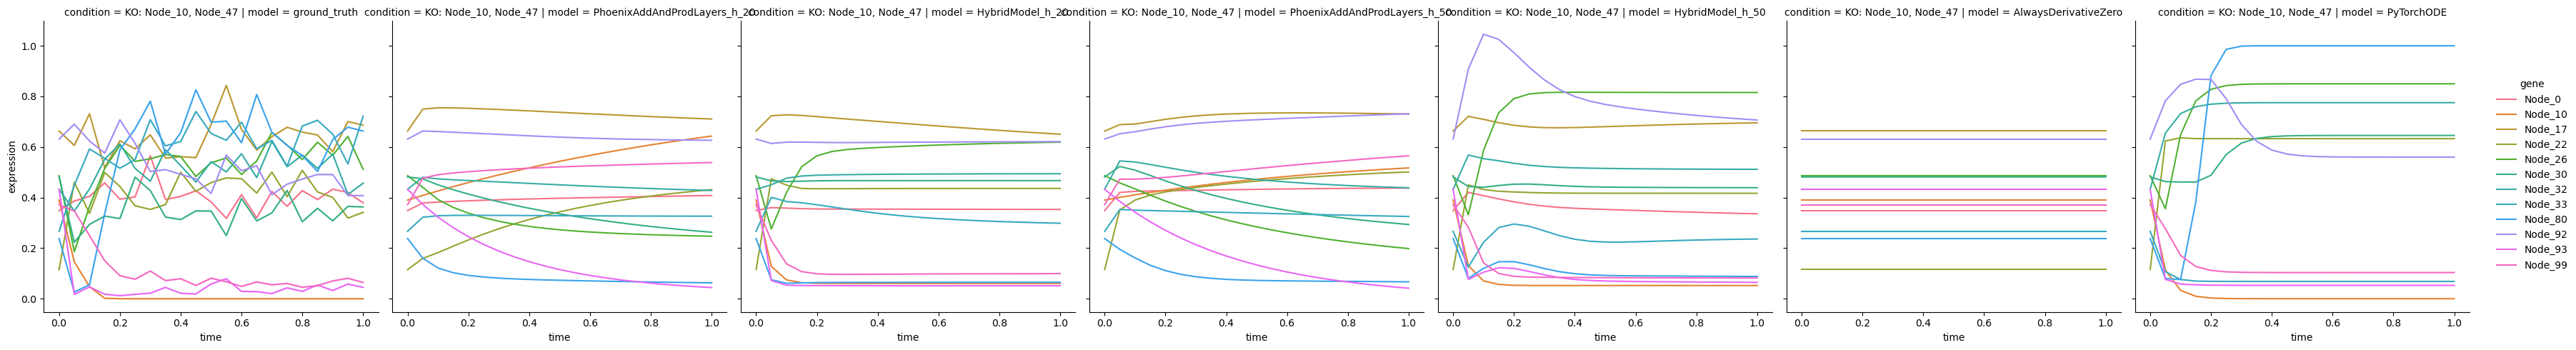

In [49]:
tidy_df_double_ko.plot_model_plots()

In [ ]:
g = tidy_df_double_ko.plot_mse_per_gene(split_by_condition_in_mm=True); 
g.figure.suptitle("Per-gene MSE for Double knockouts")
plt.tight_layout()
# plt.show()
plt.savefig(fig_dir / 'per_gene_mse_double_ko_split_by_ko_in_mm.svg')

In [ ]:
tidy_df_double_ko.plot_r2()
# plt.show()
plt.savefig(fig_dir / 'r2_plot_double_ko_split_by_ko_in_mm.eps')

In [ ]:
tidy_df_double_ko.kde_plot(subsample_first=True);plt.show()

In [ ]:
tidy_df_double_ko.plot_scatterplot();plt.show()

## Loss

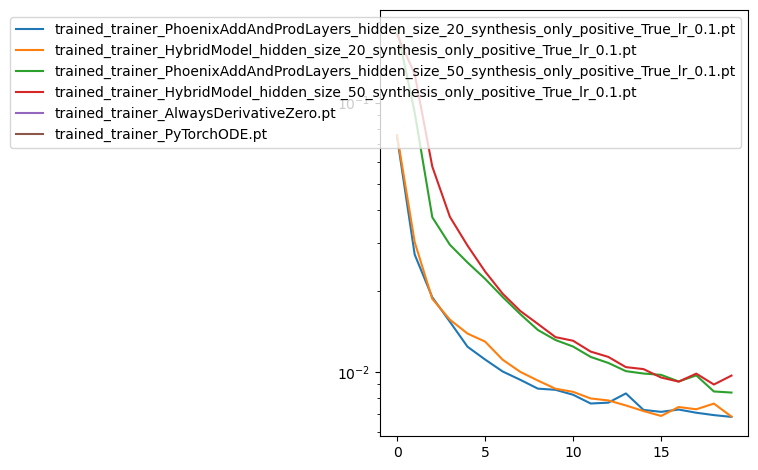

In [40]:
for result in result_list.trainer_list:
    # print(result.loss_history)
    plt.plot(result.loss_history, label=result.get_save_file_name())
plt.legend()
plt.yscale('log')
# plt.xscale('log')
plt.tight_layout()
plt.show()
# plt.savefig(fig_dir / 'loss_history_plot.svg')